
# Classificação de Cédulas com Aprendizado de Máquina

## 1. Introdução

Este projeto tem como objetivo desenvolver uma esteira de aprendizado de máquina para classificar cédulas como autênticas ou falsificadas, utilizando o algoritmo XGBoost.

A base de dados utilizada será a Banknote Authentication, disponibilizada pelo UCI Machine Learning Repository. Ela possui 1.372 registros e quatro características numéricas extraídas de imagens de cédulas.

Etapas: análise dos dados, preparação e transformação, divisão em treino, validação e teste, treinamento do modelo, avaliação dos resultados e predição.


### Bibliotecas utilizadas

In [ ]:
# Instalando as bibliotecas necessárias
%pip install scikit-learn matplotlib "cloudpickle==2.2.1"


## 2. Carregamento da base de dados


In [1]:

import pandas as pd

# Carregando a base Banknote Authentication
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"

colunas = ["variance", "skewness", "curtosis", "entropy", "class"]

df = pd.read_csv(url, header=None, names=colunas)

# Exibindo os cinco primeiros registros
df.head()


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0



## 3. Análise exploratória dos dados

Análise da base de dados: quantidade de registros, tipos de dados, estatísticas e distribuição das classes.


In [2]:

# Verificando a quantidade de linhas e colunas
print("Dimensões da base:", df.shape)

# Exibindo informações gerais
df.info()


Dimensões da base: (1372, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB


In [3]:

# Estatísticas descritivas da base
df.describe()


,variance,skewness,curtosis,entropy,class
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


In [4]:

# Quantidade de registros por classe
print("Distribuição das classes:")
print(df["class"].value_counts())

# Verificando valores ausentes
print("\nValores ausentes:")
print(df.isnull().sum())


Distribuição das classes:
class
0    762
1    610
Name: count, dtype: int64

Valores ausentes:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64



## 4. Preparação e transformação dos dados

Preparação dos dados: cópia da base original e remoção de registros duplicados.


In [6]:
# Criando uma cópia da base original
df_prep = df.copy()

In [7]:

# Verificando linhas duplicadas
duplicadas = df_prep.duplicated().sum()

print("Quantidade de linhas duplicadas:", duplicadas)

# Removendo registros duplicados, caso existam
df_prep = df_prep.drop_duplicates().reset_index(drop=True)

print("Quantidade de registros após a transformação:", len(df_prep))


Quantidade de linhas duplicadas: 24
Quantidade de registros após a transformação: 1348


In [8]:

# Verificando as dimensões da base
print("Base original:", df.shape)
print("Base preparada:", df_prep.shape)

# Exibindo os primeiros registros
df_prep.head()


Base original: (1372, 5)
Base preparada: (1348, 5)


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0



## 5. Divisão dos dados

Divisão da base em três conjuntos: treinamento (60%), validação (20%) e teste (20%).


In [11]:

from sklearn.model_selection import train_test_split

# Separando os dados da classificação
X = df_prep.drop(columns=["class"])
y = df_prep["class"]

# Separando 20% dos dados para teste
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Separando os dados restantes em treino e validação
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.25,
    random_state=42,
    stratify=y_temp
)

print("Treinamento:", len(X_train))
print("Validação:", len(X_val))
print("Teste:", len(X_test))


Treinamento: 808
Validação: 270
Teste: 270



## 6. Normalização dos dados

Normalização da coluna variance, usando os valores mínimo e máximo do conjunto de treinamento.


In [12]:
# Criando cópias dos conjuntos
X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()

# Calculando o mínimo e máximo do treinamento
valor_min = X_train["variance"].min()
valor_max = X_train["variance"].max()

# Normalizando a coluna variance nos três conjuntos
for conjunto in [X_train, X_val, X_test]:
    conjunto["variance_scaled"] = (
        (conjunto["variance"] - valor_min) / (valor_max - valor_min)
    )

# Mostrando os primeiros registros
X_train[["variance", "variance_scaled"]].head()

,variance,variance_scaled
51,3.14520,0.748769
257,1.81140,0.650734
779,0.91315,0.584713
1240,-6.65100,0.028746
78,1.13170,0.600776



## 7. Treinamento do modelo XGBoost

Treinamento do modelo de classificação usando o algoritmo XGBoost no Amazon SageMaker.


In [13]:

# Importando as bibliotecas e verificando as versões

import sagemaker
import boto3

print("SageMaker:", sagemaker.__version__)
print("Boto3:", boto3.__version__)



sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/ec2-user/.config/sagemaker/config.yaml
SageMaker: 2.189.0
Boto3: 1.43.124


In [16]:

# Configurando o ambiente AWS
sessao = sagemaker.Session()
regiao = boto3.Session().region_name
role = sagemaker.get_execution_role()

# Bucket utilizado no laboratório AWS Academy
# Para executar em outro ambiente, alterar para um bucket com acesso permitido
bucket = "c232372a5850161l18481798t1w802942640863-labbucket-8t6z5oivytra"

# Verificando o acesso ao bucket
s3 = boto3.client("s3")

try:
    s3.head_bucket(Bucket=bucket)
    print("Bucket acessível!")
except Exception as erro:
    print("Erro ao acessar o bucket:", erro)

print("Região:", regiao)
print("Bucket:", bucket)


sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/ec2-user/.config/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/ec2-user/.config/sagemaker/config.yaml
Bucket acessível!
Região: us-east-1
Bucket: c232372a5850161l18481798t1w802942640863-labbucket-8t6z5oivytra



## 8. Preparação dos arquivos para o SageMaker

Os conjuntos de treinamento, validação e teste são convertidos para arquivos CSV, permitindo sua utilização no processo de aprendizado de máquina.


In [13]:
# Colocando a classificação na primeira coluna
treino = pd.concat([y_train, X_train], axis=1)
validacao = pd.concat([y_val, X_val], axis=1)
teste = pd.concat([y_test, X_test], axis=1)

# Salvando os conjuntos em arquivos CSV
treino.to_csv("train.csv", index=False, header=False)
validacao.to_csv("validation.csv", index=False, header=False)
teste.to_csv("test.csv", index=False, header=False)

# Verificando a quantidade de registros
print("Treino:", treino.shape)
print("Validação:", validacao.shape)
print("Teste:", teste.shape)

Treino: (808, 6)
Validação: (270, 6)
Teste: (270, 6)



## 9. Armazenamento dos dados no Amazon S3

Enviando os arquivos de treino, validação e teste para o Amazon S3, para serem usados no treinamento do modelo.


In [18]:

# Definindo a pasta do projeto no S3
prefixo = "banknote-classification"

# Enviando os arquivos para o S3
s3.upload_file("train.csv", bucket, f"{prefixo}/train/train.csv")
s3.upload_file("validation.csv", bucket, f"{prefixo}/validation/validation.csv")
s3.upload_file("test.csv", bucket, f"{prefixo}/test/test.csv")

# Salvando os caminhos dos arquivos no S3
s3_train = f"s3://{bucket}/{prefixo}/train/train.csv"
s3_validation = f"s3://{bucket}/{prefixo}/validation/validation.csv"
s3_test = f"s3://{bucket}/{prefixo}/test/test.csv"

print("Arquivos enviados para o S3 com sucesso!")
print("Treinamento:", s3_train)
print("Validação:", s3_validation)
print("Teste:", s3_test)


Arquivos enviados para o S3 com sucesso!
Treinamento: s3://c232372a5850161l18481798t1w802942640863-labbucket-8t6z5oivytra/banknote-classification/train/train.csv
Validação: s3://c232372a5850161l18481798t1w802942640863-labbucket-8t6z5oivytra/banknote-classification/validation/validation.csv
Teste: s3://c232372a5850161l18481798t1w802942640863-labbucket-8t6z5oivytra/banknote-classification/test/test.csv



## 10. Configuração do modelo XGBoost

Configuração do modelo XGBoost no Amazon SageMaker para classificar as cédulas.


In [19]:

from sagemaker import image_uris
from sagemaker.estimator import Estimator

# Obtendo a imagem do XGBoost no SageMaker
container = image_uris.retrieve(
    framework="xgboost",
    region=regiao,
    version="1.7-1"
)

# Configurando o modelo
modelo = Estimator(
    image_uri=container,
    role=role,
    instance_count=1,
    instance_type="ml.m5.large",
    output_path=f"s3://{bucket}/banknote-classification/output",
    sagemaker_session=sessao
)

# Definindo os parâmetros do algoritmo
modelo.set_hyperparameters(
    objective="binary:logistic",
    num_round=100,
    max_depth=5,
    eta=0.2,
    eval_metric="logloss"
)

print("Modelo XGBoost configurado com sucesso!")


Modelo XGBoost configurado com sucesso!



## 11. Treinamento do modelo

Treinamento do modelo XGBoost usando os arquivos de treino e validação armazenados no Amazon S3.


In [20]:

from sagemaker.inputs import TrainingInput

# Definindo os dados de treinamento e validação
dados_treino = TrainingInput(
    s3_data=s3_train,
    content_type="text/csv"
)

dados_validacao = TrainingInput(
    s3_data=s3_validation,
    content_type="text/csv"
)

# Iniciando o treinamento
modelo.fit({
    "train": dados_treino,
    "validation": dados_validacao
})

print("Treinamento finalizado!")


INFO:sagemaker:Creating training-job with name: sagemaker-xgboost-2026-11-17-19-07-41-321


2026-11-17 19:07:41 Starting - Starting the training job...
2026-11-17 19:08:00 Starting - Preparing the instances for training...
2026-11-17 19:08:25 Downloading - Downloading input data.........
2026-11-17 19:09:56 Downloading - Downloading the training image...
2026-11-17 19:10:32 Training - Training image download completed. Training in progress.
2026-11-17 19:10:32 Uploading - Uploading generated training model...
2026-11-17 19:10:50 Completed - Training job completed
..Training seconds: 144
Billable seconds: 144
Treinamento finalizado!



## 12. Avaliação do modelo

Avaliação do modelo treinado, usando a acurácia e a matriz de confusão para verificar os resultados.


In [21]:

# Verificando o resultado do treinamento
print("Nome do treinamento:")
print(modelo.latest_training_job.name)

print("\nLocal onde o modelo foi salvo:")
print(modelo.model_data)


Nome do treinamento:
sagemaker-xgboost-2026-11-17-19-07-41-321

Local onde o modelo foi salvo:
s3://c232372a5850161l18481798t1w802942640863-labbucket-8t6z5oivytra/banknote-classification/output/sagemaker-xgboost-2026-11-17-19-07-41-321/output/model.tar.gz



### Implantação do modelo para realizar previsões

O modelo treinado será implantado no Amazon SageMaker para permitir a classificação de novos registros.


In [23]:

from sagemaker.serializers import CSVSerializer
from sagemaker.deserializers import CSVDeserializer

# Implantando o modelo treinado
predictor = modelo.deploy(
    initial_instance_count=1,
    instance_type="ml.m5.large"
)

# Configurando o formato dos dados
predictor.serializer = CSVSerializer()
predictor.deserializer = CSVDeserializer()

print("Modelo implantado com sucesso!")


INFO:sagemaker:Creating model with name: sagemaker-xgboost-2026-11-17-19-15-14-576
INFO:sagemaker:Creating endpoint-config with name sagemaker-xgboost-2026-11-17-19-15-14-576
INFO:sagemaker:Creating endpoint with name sagemaker-xgboost-2026-11-17-19-15-14-576


--------!Modelo implantado com sucesso!



### Previsões com o conjunto de teste

O modelo implantado será utilizado para realizar previsões com os dados de teste, permitindo comparar os resultados previstos com as classificações reais.


In [24]:

import numpy as np

# Enviando os dados de teste para o modelo
resposta = predictor.predict(X_test.to_numpy())

# Convertendo as respostas em probabilidades
probabilidades = np.array(resposta, dtype=float).flatten()

# Convertendo as probabilidades em classes 0 ou 1
previsoes = (probabilidades >= 0.5).astype(int)

# Comparando os resultados
resultados = pd.DataFrame({
    "Classe real": y_test.to_numpy(),
    "Classe prevista": previsoes
})

# Exibindo os primeiros resultados
resultados.head(10)


,Classe real,Classe prevista
0,0,0
1,1,1
2,0,0
3,0,0
4,1,1
5,0,0
6,0,0
7,0,0
8,0,0
9,1,1



### Acurácia e matriz de confusão

Cálculo da acurácia e criação da matriz de confusão para verificar os acertos e erros do modelo.


INFO:matplotlib.font_manager:Failed to extract font properties from /usr/share/fonts/cantarell/Cantarell-VF.otf: Can not load face (SFNT font table missing; error code 0x8e)
INFO:matplotlib.font_manager:generated new fontManager


Acurácia do modelo: 98.52%

Matriz de confusão:
[[144   4]
 [  0 122]]


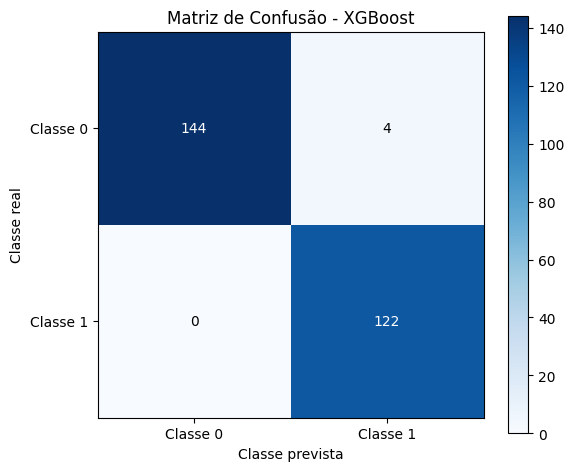

In [27]:

from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt

# Calculando a acurácia
acuracia = accuracy_score(y_test, previsoes)

print(f"Acurácia do modelo: {acuracia * 100:.2f}%")

# Criando a matriz de confusão
matriz = confusion_matrix(y_test, previsoes, labels=[0, 1])

print("\nMatriz de confusão:")
print(matriz)

# Exibindo a matriz em formato de gráfico
fig, ax = plt.subplots(figsize=(6, 5))

imagem = ax.imshow(matriz, cmap="Blues")
fig.colorbar(imagem, ax=ax)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels(["Classe 0", "Classe 1"])
ax.set_yticklabels(["Classe 0", "Classe 1"])

ax.set_xlabel("Classe prevista")
ax.set_ylabel("Classe real")
ax.set_title("Matriz de Confusão - XGBoost")

# Exibindo os valores dentro dos quadrados
for i in range(2):
    for j in range(2):
        ax.text(
            j, i, matriz[i, j],
            ha="center", va="center",
            color="white" if matriz[i, j] > matriz.max() / 2 else "black"
        )

plt.tight_layout()
plt.show()



### Previsão individual com o modelo implantado

Previsão de uma cédula do conjunto de teste para verificar a classificação feita pelo modelo.


In [28]:

# Selecionando uma cédula do conjunto de teste
cedula = X_test.iloc[[0]]

# Realizando a previsão
resposta_individual = predictor.predict(cedula.to_numpy())

# Convertendo a resposta em classe
probabilidade = float(np.array(resposta_individual).flatten()[0])
classe_prevista = int(probabilidade >= 0.5)

# Consultando a classificação verdadeira
classe_real = int(y_test.iloc[0])

print("Classe real:", classe_real)
print("Classe prevista:", classe_prevista)
print(f"Probabilidade da classe 1: {probabilidade:.2%}")

if classe_prevista == classe_real:
    print("Resultado: previsão correta!")
else:
    print("Resultado: previsão incorreta.")


Classe real: 0
Classe prevista: 0
Probabilidade da classe 1: 0.06%
Resultado: previsão correta!


### 13. Salvamento do modelo e encerramento do endpoint
Download do modelo treinado e exclusão do endpoint após a realização das previsões.

In [30]:


# Baixando o modelo treinado do S3
caminho_modelo = modelo.model_data

s3.download_file(
    bucket,
    caminho_modelo.replace(f"s3://{bucket}/", ""),
    "model.tar.gz"
)

print("Modelo baixado com sucesso!")



Modelo baixado com sucesso!


In [31]:

predictor.delete_endpoint()
print("Solicitação de exclusão do endpoint enviada!")


INFO:sagemaker:Deleting endpoint configuration with name: sagemaker-xgboost-2026-11-17-19-15-14-576
INFO:sagemaker:Deleting endpoint with name: sagemaker-xgboost-2026-11-17-19-15-14-576


Solicitação de exclusão do endpoint enviada!
